In [1]:
# ============================================================
# SECTION 3.5 FINAL VERIFICATION — LOCAL JUPYTER
# CELL 1 — Verify local PHEME dataset
# ============================================================

import os
import pandas as pd
import numpy as np
import json

base_dir = r"D:\PhD Material\Paper on Diffusion based  Node classification\Pheme\Update\all-rnr-annotated-threads_1"

RETAINED_EVENTS = {
    "charliehebdo-all-rnr-threads",
    "ferguson-all-rnr-threads",
    "germanwings-crash-all-rnr-threads",
    "sydneysiege-all-rnr-threads"
}

print("=" * 72)
print("LOCAL PHEME DATASET CHECK")
print("=" * 72)

print("\nDataset path:")
print(base_dir)

print("\nDataset exists:", os.path.exists(base_dir))

if os.path.exists(base_dir):

    folders = [
        x for x in os.listdir(base_dir)
        if os.path.isdir(os.path.join(base_dir, x))
    ]

    print("\nRetained event folders:")

    for event in sorted(RETAINED_EVENTS):
        exists = event in folders
        print(f"{event:40s}  {'FOUND' if exists else 'MISSING'}")

    all_found = all(
        event in folders
        for event in RETAINED_EVENTS
    )

    print("\n" + "=" * 72)

    if all_found:
        print("READY — all four required PHEME events are available locally.")
    else:
        print("STOP — one or more required event folders are missing.")

else:
    print("\nSTOP — dataset path was not found.")

LOCAL PHEME DATASET CHECK

Dataset path:
D:\PhD Material\Paper on Diffusion based  Node classification\Pheme\Update\all-rnr-annotated-threads_1

Dataset exists: True

Retained event folders:
charliehebdo-all-rnr-threads              FOUND
ferguson-all-rnr-threads                  FOUND
germanwings-crash-all-rnr-threads         FOUND
sydneysiege-all-rnr-threads               FOUND

READY — all four required PHEME events are available locally.


In [2]:
# ============================================================
# SECTION 3.5 FINAL VERIFICATION — LOCAL JUPYTER
# CELL 2 — Load frozen final topology list
# ============================================================

import os
import pandas as pd

topology_file = (
    r"D:\PhD Material\Paper on Diffusion based  Node classification"
    r"\Pheme\Update\all-rnr-annotated-threads_1"
    r"\final_topology_labels.csv"
)
print("=" * 72)
print("FROZEN TOPOLOGY FILE CHECK")
print("=" * 72)

print("\nFile:")
print(topology_file)

print("\nExists:", os.path.exists(topology_file))

if not os.path.exists(topology_file):
    raise FileNotFoundError(
        "final_topology_labels.csv was not found at the specified location."
    )

# Important: preserve thread IDs as strings
df_final = pd.read_csv(
    topology_file,
    dtype={"thread_id": str}
)

print("\nShape:", df_final.shape)

print("\nColumns:")
print(df_final.columns.tolist())

print("\nLabel counts:")
print(df_final["label"].value_counts().sort_index())

print("\nEvent counts:")
print(df_final["event"].value_counts().sort_index())

print("\nEvent x label:")
print(
    df_final
    .groupby(["event", "label"])
    .size()
    .unstack(fill_value=0)
)

print("\nTopology counts:")
print(df_final["topology"].value_counts())

print("\nDuplicate event/thread records:")
print(
    df_final.duplicated(
        subset=["event", "thread_id"]
    ).sum()
)

print("\nMissing thread IDs:")
print(df_final["thread_id"].isna().sum())

print("\nFirst five records:")
display(df_final.head())

print("\n" + "=" * 72)

if len(df_final) == 4072:
    print("PASS — frozen file contains exactly 4,072 cascades.")
else:
    print(
        "STOP — expected 4,072 cascades but found",
        len(df_final)
    )

FROZEN TOPOLOGY FILE CHECK

File:
D:\PhD Material\Paper on Diffusion based  Node classification\Pheme\Update\all-rnr-annotated-threads_1\final_topology_labels.csv

Exists: True

Shape: (4072, 8)

Columns:
['event', 'thread_id', 'label', 'num_nodes', 'num_edges', 'root_edge_dominance', 'max_depth_recomputed', 'topology']

Label counts:
label
0    2851
1    1221
Name: count, dtype: int64

Event counts:
event
charliehebdo-all-rnr-threads         1801
ferguson-all-rnr-threads              926
germanwings-crash-all-rnr-threads     264
sydneysiege-all-rnr-threads          1081
Name: count, dtype: int64

Event x label:
label                                 0    1
event                                       
charliehebdo-all-rnr-threads       1412  389
ferguson-all-rnr-threads            683  243
germanwings-crash-all-rnr-threads   130  134
sydneysiege-all-rnr-threads         626  455

Topology counts:
topology
star      1950
hybrid    1661
chain      461
Name: count, dtype: int64

Duplicate e

,event,thread_id,label,num_nodes,num_edges,root_edge_dominance,max_depth_recomputed,topology
0,charliehebdo-all-rnr-threads,5.53173E+17,0,12,11,0.909091,2,star
1,charliehebdo-all-rnr-threads,5.53172E+17,0,14,12,0.833333,2,star
2,charliehebdo-all-rnr-threads,5.53172E+17,0,22,21,0.619048,8,hybrid
3,charliehebdo-all-rnr-threads,5.53169E+17,0,11,10,0.900000,2,star
4,charliehebdo-all-rnr-threads,5.5317E+17,0,21,20,0.700000,3,hybrid



PASS — frozen file contains exactly 4,072 cascades.


In [3]:
# ============================================================
# SECTION 3.5 FINAL VERIFICATION — LOCAL JUPYTER
# CELL 3 — Reconstruct all PHEME edges locally
# Uses actual directory names, preserving exact thread IDs
# ============================================================

import os
import json
import pandas as pd

base_dir = (
    r"D:\PhD Material\Paper on Diffusion based  Node classification"
    r"\Pheme\Update\all-rnr-annotated-threads_1"
)

RETAINED_EVENTS = {
    "charliehebdo-all-rnr-threads",
    "ferguson-all-rnr-threads",
    "germanwings-crash-all-rnr-threads",
    "sydneysiege-all-rnr-threads"
}


def iter_structure_edges(struct_obj):
    """
    Extract parent -> child edges from nested
    PHEME structure.json.
    """

    edges = []

    def dfs(parent, subtree):

        if isinstance(subtree, dict):

            for child, child_subtree in subtree.items():

                edges.append(
                    (str(parent), str(child))
                )

                dfs(
                    str(child),
                    child_subtree
                )

    if isinstance(struct_obj, dict):

        for root, subtree in struct_obj.items():

            dfs(
                str(root),
                subtree
            )

    return edges


rows = []
failed = []

for event in sorted(RETAINED_EVENTS):

    print("\nProcessing:", event)

    for label_type in ["non-rumours", "rumours"]:

        label = 0 if label_type == "non-rumours" else 1

        label_path = os.path.join(
            base_dir,
            event,
            label_type
        )

        if not os.path.exists(label_path):
            print("MISSING:", label_path)
            continue

        thread_folders = [
            x for x in os.listdir(label_path)
            if os.path.isdir(
                os.path.join(label_path, x)
            )
            and not x.startswith("._")
        ]

        print(
            f"  {label_type}: "
            f"{len(thread_folders):,} folders"
        )

        for thread_id in thread_folders:

            structure_path = os.path.join(
                label_path,
                thread_id,
                "structure.json"
            )

            if not os.path.exists(structure_path):
                continue

            try:

                with open(
                    structure_path,
                    "r",
                    encoding="utf-8",
                    errors="ignore"
                ) as f:

                    structure = json.load(f)

                edges = iter_structure_edges(
                    structure
                )

                for parent, child in edges:

                    rows.append({
                        "event": event,
                        "thread_id": str(thread_id),
                        "label": label,
                        "parent_id": parent,
                        "child_id": child
                    })

            except Exception as e:

                failed.append(
                    (event, thread_id, str(e))
                )


df_edges = pd.DataFrame(rows)


print("\n" + "=" * 72)
print("LOCAL EDGE RECONSTRUCTION COMPLETE")
print("=" * 72)

print("\nTotal edges:",
      len(df_edges))

print(
    "Threads represented:",
    df_edges[
        ["event", "thread_id", "label"]
    ].drop_duplicates().shape[0]
)

print("Failed JSON files:",
      len(failed))

print("\nEvent-wise edges:")

print(
    df_edges["event"]
    .value_counts()
    .sort_index()
)

print("\nThread-ID example:")
print(
    df_edges["thread_id"]
    .iloc[0]
)

print("\nThread-ID Python type:")
print(
    type(df_edges["thread_id"].iloc[0])
)

print("\nCELL 3 COMPLETE")


Processing: charliehebdo-all-rnr-threads
  non-rumours: 1,621 folders
  rumours: 458 folders

Processing: ferguson-all-rnr-threads
  non-rumours: 859 folders
  rumours: 284 folders

Processing: germanwings-crash-all-rnr-threads
  non-rumours: 231 folders
  rumours: 238 folders

Processing: sydneysiege-all-rnr-threads
  non-rumours: 699 folders
  rumours: 522 folders

LOCAL EDGE RECONSTRUCTION COMPLETE

Total edges: 82530
Threads represented: 4587
Failed JSON files: 0

Event-wise edges:
event
charliehebdo-all-rnr-threads         35115
ferguson-all-rnr-threads             21216
germanwings-crash-all-rnr-threads     3962
sydneysiege-all-rnr-threads          22237
Name: count, dtype: int64

Thread-ID example:
552784600502915072

Thread-ID Python type:
<class 'str'>

CELL 3 COMPLETE


In [4]:
# ============================================================
# SECTION 3.5 FINAL VERIFICATION — LOCAL JUPYTER
# CELL 4 — Compute structural metrics and apply >=5 node filter
# NO ML TRAINING
# ============================================================

import pandas as pd
import numpy as np
from collections import defaultdict, deque


def compute_structural_metrics(edge_df, thread_id):

    parents = edge_df["parent_id"].astype(str).tolist()
    children = edge_df["child_id"].astype(str).tolist()

    nodes = set(parents) | set(children)

    adjacency = defaultdict(list)
    indeg = defaultdict(int)
    outdeg = defaultdict(int)

    for u, v in zip(parents, children):
        adjacency[u].append(v)
        indeg[v] += 1
        outdeg[u] += 1

    # --------------------------------------------------------
    # Actual PHEME source tweet = thread ID
    # --------------------------------------------------------

    root = str(thread_id)

    if root not in nodes:
        raise ValueError(
            f"Source tweet {root} not found among graph nodes."
        )

    # --------------------------------------------------------
    # Basic graph properties
    # --------------------------------------------------------

    n_nodes = len(nodes)
    n_edges = len(parents)

    # --------------------------------------------------------
    # Depth from actual source tweet
    # --------------------------------------------------------

    depth = {root: 0}
    queue = deque([root])

    while queue:

        u = queue.popleft()

        for v in adjacency.get(u, []):

            if v not in depth:
                depth[v] = depth[u] + 1
                queue.append(v)

    max_depth = max(depth.values()) if depth else 0

    # --------------------------------------------------------
    # Leaf ratio
    # --------------------------------------------------------

    leaves = [
        node for node in nodes
        if outdeg[node] == 0
    ]

    leaf_ratio = (
        len(leaves) / n_nodes
        if n_nodes > 0
        else 0.0
    )

    # --------------------------------------------------------
    # Mean branching of internal nodes
    # --------------------------------------------------------

    internal_nodes = [
        node for node in nodes
        if outdeg[node] > 0
    ]

    mean_branching_internal = (
        float(
            np.mean(
                [outdeg[node] for node in internal_nodes]
            )
        )
        if internal_nodes
        else 0.0
    )

    # --------------------------------------------------------
    # Directed graph density
    # --------------------------------------------------------

    density = (
        n_edges /
        (n_nodes * (n_nodes - 1))
        if n_nodes > 1
        else 0.0
    )

    # --------------------------------------------------------
    # Root-edge dominance
    # --------------------------------------------------------

    root_edges = outdeg[root]

    root_edge_dominance = (
        root_edges / n_edges
        if n_edges > 0
        else 0.0
    )

    # --------------------------------------------------------
    # Audit information
    # --------------------------------------------------------

    zero_indegree_nodes = [
        node for node in nodes
        if indeg[node] == 0
    ]

    n_reachable = len(depth)

    return {
        "n_nodes": int(n_nodes),
        "n_edges": int(n_edges),
        "max_depth": int(max_depth),
        "leaf_ratio": float(leaf_ratio),
        "mean_branching_internal":
            float(mean_branching_internal),
        "density": float(density),
        "root_edge_dominance":
            float(root_edge_dominance),
        "n_zero_indegree":
            int(len(zero_indegree_nodes)),
        "n_reachable_from_source":
            int(n_reachable),
        "n_disconnected_from_source":
            int(n_nodes - n_reachable)
    }


# ============================================================
# Calculate metrics for all 4,587 pre-filter threads
# ============================================================

metric_rows = []
metric_errors = []

grouped = df_edges.groupby(
    ["event", "thread_id", "label"],
    sort=False
)

total_groups = grouped.ngroups

print("Threads to process:", total_groups)

for i, ((event, thread_id, label), g) in enumerate(
    grouped, start=1
):

    try:

        metrics = compute_structural_metrics(
            g,
            thread_id
        )

        metrics.update({
            "event": event,
            "thread_id": str(thread_id),
            "label": int(label)
        })

        metric_rows.append(metrics)

    except Exception as e:

        metric_errors.append({
            "event": event,
            "thread_id": thread_id,
            "error": str(e)
        })

    if i % 500 == 0:
        print(
            f"Processed {i:,} / "
            f"{total_groups:,}"
        )


df_metrics_all = pd.DataFrame(metric_rows)


# ============================================================
# Apply manuscript filtering criterion: N >= 5
# ============================================================

df_metrics_final = (
    df_metrics_all[
        df_metrics_all["n_nodes"] >= 5
    ]
    .copy()
    .reset_index(drop=True)
)


# ============================================================
# Audit final dataset
# ============================================================

print("\n" + "=" * 72)
print("FINAL STRUCTURAL DATASET AUDIT")
print("=" * 72)

print("\nPre-filter threads:",
      len(df_metrics_all))

print("Retained N >= 5:",
      len(df_metrics_final))

print("Removed N < 5:",
      len(df_metrics_all) - len(df_metrics_final))

print("\nMetric errors:",
      len(metric_errors))

print("\nLabel counts:")
print(
    df_metrics_final["label"]
    .value_counts()
    .sort_index()
)

print("\nEvent x label:")
print(
    df_metrics_final
    .groupby(["event", "label"])
    .size()
    .unstack(fill_value=0)
)

print("\nZero-indegree node count:")
print(
    df_metrics_final["n_zero_indegree"]
    .value_counts()
    .sort_index()
)

print("\nCascades with disconnected nodes:")
print(
    (
        df_metrics_final[
            "n_disconnected_from_source"
        ] > 0
    ).sum()
)

print("\nFirst five final rows:")
display(df_metrics_final.head())


# ============================================================
# Save permanently
# ============================================================

output_structural = (
    r"D:\PhD Material\Paper on Diffusion based  Node classification"
    r"\Pheme\Update\final_structural_metrics_4072.csv"
)

df_metrics_final.to_csv(
    output_structural,
    index=False
)

print("\n" + "=" * 72)
print("SAVED PERMANENTLY:")
print(output_structural)
print("=" * 72)

Threads to process: 4587
Processed 500 / 4,587
Processed 1,000 / 4,587
Processed 1,500 / 4,587
Processed 2,000 / 4,587
Processed 2,500 / 4,587
Processed 3,000 / 4,587
Processed 3,500 / 4,587
Processed 4,000 / 4,587
Processed 4,500 / 4,587

FINAL STRUCTURAL DATASET AUDIT

Pre-filter threads: 4587
Retained N >= 5: 4071
Removed N < 5: 516

Metric errors: 0

Label counts:
label
0    2851
1    1220
Name: count, dtype: int64

Event x label:
label                                 0    1
event                                       
charliehebdo-all-rnr-threads       1412  389
ferguson-all-rnr-threads            683  243
germanwings-crash-all-rnr-threads   130  134
sydneysiege-all-rnr-threads         626  454

Zero-indegree node count:
n_zero_indegree
1    4056
2       8
3       2
4       2
5       1
6       1
7       1
Name: count, dtype: int64

Cascades with disconnected nodes:
15

First five final rows:


,n_nodes,n_edges,max_depth,leaf_ratio,mean_branching_internal,density,root_edge_dominance,n_zero_indegree,n_reachable_from_source,n_disconnected_from_source,event,thread_id,label
0,40,39,14,0.275000,1.344828,0.025000,0.205128,1,40,0,charliehebdo-all-rnr-threads,552784600502915072,0
1,10,9,2,0.800000,4.500000,0.100000,0.888889,1,10,0,charliehebdo-all-rnr-threads,552784898743099392,0
2,31,30,6,0.451613,1.764706,0.032258,0.166667,1,31,0,charliehebdo-all-rnr-threads,552785391653494784,0
3,6,5,2,0.666667,2.500000,0.166667,0.800000,1,6,0,charliehebdo-all-rnr-threads,552786116404072448,0
4,11,10,2,0.727273,3.333333,0.090909,0.800000,1,11,0,charliehebdo-all-rnr-threads,552786299875520512,0



SAVED PERMANENTLY:
D:\PhD Material\Paper on Diffusion based  Node classification\Pheme\Update\final_structural_metrics_4072.csv


In [5]:
# ============================================================
# CELL 5 — Investigate Sydney Siege rumour discrepancy
# ============================================================

# All Sydney rumour threads BEFORE >=5 filtering
sydney_rumour_all = df_metrics_all[
    (df_metrics_all["event"] == "sydneysiege-all-rnr-threads") &
    (df_metrics_all["label"] == 1)
].copy()

# Retained by current reconstruction
sydney_rumour_retained = sydney_rumour_all[
    sydney_rumour_all["n_nodes"] >= 5
].copy()

# Excluded because N < 5
sydney_rumour_excluded = sydney_rumour_all[
    sydney_rumour_all["n_nodes"] < 5
].copy()

print("=" * 72)
print("SYDNEY SIEGE RUMOUR AUDIT")
print("=" * 72)

print("\nTotal Sydney rumour threads represented:",
      len(sydney_rumour_all))

print("Retained with N >= 5:",
      len(sydney_rumour_retained))

print("Excluded with N < 5:",
      len(sydney_rumour_excluded))

print("\nExcluded size distribution:")
print(
    sydney_rumour_excluded["n_nodes"]
    .value_counts()
    .sort_index()
)

print("\nExcluded Sydney rumour threads:")
display(
    sydney_rumour_excluded[
        [
            "thread_id",
            "n_nodes",
            "n_edges",
            "max_depth",
            "n_zero_indegree",
            "n_reachable_from_source",
            "n_disconnected_from_source"
        ]
    ].sort_values(
        ["n_nodes", "thread_id"],
        ascending=[False, True]
    )
)

SYDNEY SIEGE RUMOUR AUDIT

Total Sydney rumour threads represented: 499
Retained with N >= 5: 454
Excluded with N < 5: 45

Excluded size distribution:
n_nodes
2     7
3    18
4    20
Name: count, dtype: int64

Excluded Sydney rumour threads:


,thread_id,n_nodes,n_edges,max_depth,n_zero_indegree,n_reachable_from_source,n_disconnected_from_source
4118,544274585697280000,4,3,1,1,4,0
4163,544283745939767296,4,3,1,1,4,0
4226,544296772592336896,4,3,1,1,4,0
4249,544302851158470657,4,3,1,1,4,0
4257,544305745416581120,4,3,1,1,4,0
4259,544306402731507712,4,3,1,1,4,0
4264,544307417677189121,4,3,2,1,4,0
4332,544350712365207552,4,3,1,1,4,0
4336,544351356824604673,4,3,1,1,4,0
4339,544351967829839873,4,3,1,1,4,0


In [6]:
# ============================================================
# CHECK RAW DOWNLOADED final_topology_labels FILE
# Do NOT open/save it through Excel
# ============================================================

import os
import pandas as pd

raw_file = (
    r"D:\PhD Material\Paper on Diffusion based  Node classification"
    r"\Pheme\Update\final_topology_labels"
)

print("File exists:", os.path.exists(raw_file))
print("File size:", os.path.getsize(raw_file) if os.path.exists(raw_file) else "N/A")

# Read as text/CSV even though Windows is not displaying .csv
df_frozen_clean = pd.read_csv(
    raw_file,
    dtype={"thread_id": str}
)

print("\nShape:", df_frozen_clean.shape)

print("\nColumns:")
print(df_frozen_clean.columns.tolist())

print("\nFirst 10 thread IDs:")
for x in df_frozen_clean["thread_id"].head(10):
    print(x)

print("\nScientific-notation thread IDs:")
print(
    df_frozen_clean["thread_id"]
    .str.contains(
        r"[Ee]\+",
        regex=True,
        na=False
    )
    .sum()
)

print("\nDuplicate event/thread pairs:")
print(
    df_frozen_clean.duplicated(
        ["event", "thread_id"]
    ).sum()
)

print("\nUnique thread IDs:")
print(
    df_frozen_clean[
        ["event", "thread_id"]
    ].drop_duplicates().shape[0]
)

File exists: True
File size: 315603

Shape: (4072, 8)

Columns:
['event', 'thread_id', 'label', 'num_nodes', 'num_edges', 'root_edge_dominance', 'max_depth_recomputed', 'topology']

First 10 thread IDs:
553173371043995648
553171877464920064
553171841913602048
553168792017457154
553169622762262529
553169577228926976
553170912129056770
553171056589279233
553171741804359680
553170984824733698

Scientific-notation thread IDs:
0

Duplicate event/thread pairs:
0

Unique thread IDs:
4072


In [7]:
# ============================================================
# SECTION 3.5 — CELL 6
# Exact comparison:
# Frozen final 4,072 cascades
# vs locally reconstructed N >= 5 cascades
# ============================================================

# Make sure IDs are strings in both dataframes
df_frozen_clean["thread_id"] = (
    df_frozen_clean["thread_id"].astype(str)
)

df_metrics_final["thread_id"] = (
    df_metrics_final["thread_id"].astype(str)
)

# ------------------------------------------------------------
# Create exact (event, thread_id, label) keys
# ------------------------------------------------------------

frozen_keys = set(
    zip(
        df_frozen_clean["event"],
        df_frozen_clean["thread_id"],
        df_frozen_clean["label"].astype(int)
    )
)

reconstructed_keys = set(
    zip(
        df_metrics_final["event"],
        df_metrics_final["thread_id"],
        df_metrics_final["label"].astype(int)
    )
)

# ------------------------------------------------------------
# Set differences
# ------------------------------------------------------------

missing_from_reconstruction = (
    frozen_keys - reconstructed_keys
)

extra_in_reconstruction = (
    reconstructed_keys - frozen_keys
)

print("=" * 72)
print("EXACT FINAL-DATASET COMPARISON")
print("=" * 72)

print("\nFrozen final cascades:",
      len(frozen_keys))

print("Locally reconstructed retained cascades:",
      len(reconstructed_keys))

print("\nPresent in frozen final set but missing "
      "from reconstruction:")
print(len(missing_from_reconstruction))

for item in sorted(missing_from_reconstruction):
    print(item)

print("\nPresent in reconstruction but NOT "
      "in frozen final set:")
print(len(extra_in_reconstruction))

for item in sorted(extra_in_reconstruction):
    print(item)


# ------------------------------------------------------------
# Display complete frozen record for missing cascade(s)
# ------------------------------------------------------------

if missing_from_reconstruction:

    missing_ids = {
        x[1]
        for x in missing_from_reconstruction
    }

    print("\n" + "=" * 72)
    print("FROZEN RECORD(S) FOR MISSING CASCADE")
    print("=" * 72)

    display(
        df_frozen_clean[
            df_frozen_clean["thread_id"]
            .isin(missing_ids)
        ]
    )


# ------------------------------------------------------------
# Find same thread in PRE-FILTER reconstructed metrics
# ------------------------------------------------------------

if missing_from_reconstruction:

    print("\n" + "=" * 72)
    print("PRE-FILTER RECONSTRUCTION OF SAME THREAD")
    print("=" * 72)

    display(
        df_metrics_all[
            df_metrics_all["thread_id"]
            .isin(missing_ids)
        ][
            [
                "event",
                "thread_id",
                "label",
                "n_nodes",
                "n_edges",
                "max_depth",
                "leaf_ratio",
                "mean_branching_internal",
                "density",
                "root_edge_dominance",
                "n_zero_indegree",
                "n_reachable_from_source",
                "n_disconnected_from_source"
            ]
        ]
    )

EXACT FINAL-DATASET COMPARISON

Frozen final cascades: 4072
Locally reconstructed retained cascades: 4071

Present in frozen final set but missing from reconstruction:
1
('sydneysiege-all-rnr-threads', '544350712365207552', 1)

Present in reconstruction but NOT in frozen final set:
0

FROZEN RECORD(S) FOR MISSING CASCADE


,event,thread_id,label,num_nodes,num_edges,root_edge_dominance,max_depth_recomputed,topology
3844,sydneysiege-all-rnr-threads,544350712365207552,1,11,3,1.0,1.0,star



PRE-FILTER RECONSTRUCTION OF SAME THREAD


,event,thread_id,label,n_nodes,n_edges,max_depth,leaf_ratio,mean_branching_internal,density,root_edge_dominance,n_zero_indegree,n_reachable_from_source,n_disconnected_from_source
4332,sydneysiege-all-rnr-threads,544350712365207552,1,4,3,1,0.75,3.0,0.25,1.0,1,4,0


In [8]:
# ============================================================
# SECTION 3.5 — CELL 7
# Inspect the single discrepant Sydney Siege rumour
# ============================================================

import os
import json

thread_id = "544350712365207552"

thread_path = os.path.join(
    base_dir,
    "sydneysiege-all-rnr-threads",
    "rumours",
    thread_id
)

print("=" * 72)
print("THREAD AUDIT:", thread_id)
print("=" * 72)

print("\nThread path:")
print(thread_path)

print("\nExists:", os.path.exists(thread_path))

print("\nContents:")
for item in sorted(os.listdir(thread_path)):
    print(" -", item)


# ------------------------------------------------------------
# Inspect structure.json
# ------------------------------------------------------------

structure_path = os.path.join(
    thread_path,
    "structure.json"
)

with open(
    structure_path,
    "r",
    encoding="utf-8",
    errors="ignore"
) as f:
    structure = json.load(f)

print("\nRaw structure.json:")
print(json.dumps(structure, indent=2))


edges = iter_structure_edges(structure)

print("\nExtracted edges:")
for u, v in edges:
    print(u, "->", v)

edge_nodes = set()

for u, v in edges:
    edge_nodes.add(str(u))
    edge_nodes.add(str(v))

print("\nNodes represented by structure edges:",
      len(edge_nodes))

print("Edge count:",
      len(edges))


# ------------------------------------------------------------
# Inspect source-tweets and reactions directories
# ------------------------------------------------------------

source_dir = os.path.join(
    thread_path,
    "source-tweets"
)

reaction_dir = os.path.join(
    thread_path,
    "reactions"
)

source_files = (
    [
        x for x in os.listdir(source_dir)
        if x.endswith(".json")
        and not x.startswith("._")
    ]
    if os.path.exists(source_dir)
    else []
)

reaction_files = (
    [
        x for x in os.listdir(reaction_dir)
        if x.endswith(".json")
        and not x.startswith("._")
    ]
    if os.path.exists(reaction_dir)
    else []
)

print("\nSource tweet JSON files:",
      len(source_files))

for x in source_files:
    print(" -", x)

print("\nReaction JSON files:",
      len(reaction_files))

for x in reaction_files:
    print(" -", x)


# ------------------------------------------------------------
# Extract tweet IDs represented by JSON filenames
# ------------------------------------------------------------

source_ids = {
    os.path.splitext(x)[0]
    for x in source_files
}

reaction_ids = {
    os.path.splitext(x)[0]
    for x in reaction_files
}

all_tweet_ids = source_ids | reaction_ids

print("\nTotal tweet JSON IDs:",
      len(all_tweet_ids))

print("Source IDs:",
      len(source_ids))

print("Reaction IDs:",
      len(reaction_ids))


# ------------------------------------------------------------
# Compare thread tweet files with structure edge nodes
# ------------------------------------------------------------

missing_from_edges = (
    all_tweet_ids - edge_nodes
)

print("\nTweet IDs present in thread files but absent "
      "from structure edges:")

print("Count:", len(missing_from_edges))

for x in sorted(missing_from_edges):
    print(" -", x)


print("\n" + "=" * 72)
print("SUMMARY")
print("=" * 72)

print("Nodes from structure edges :", len(edge_nodes))
print("Nodes from tweet JSON files:", len(all_tweet_ids))
print("Frozen final num_nodes     : 11")
print("Frozen final num_edges     : 3")

THREAD AUDIT: 544350712365207552

Thread path:
D:\PhD Material\Paper on Diffusion based  Node classification\Pheme\Update\all-rnr-annotated-threads_1\sydneysiege-all-rnr-threads\rumours\544350712365207552

Exists: True

Contents:
 - ._annotation.json
 - ._reactions
 - ._source-tweets
 - ._structure.json
 - annotation.json
 - reactions
 - source-tweets
 - structure.json

Raw structure.json:
{
  "544350712365207552": {
    "544351255057813505": [],
    "544351320174772224": [],
    "544352182401638401": []
  },
  "544354905335820288": [],
  "544356405759995904": [],
  "544362235414720512": [],
  "544363228885966848": [],
  "544365021011390464": [],
  "544366589546864640": [],
  "544367122202505216": []
}

Extracted edges:
544350712365207552 -> 544351255057813505
544350712365207552 -> 544351320174772224
544350712365207552 -> 544352182401638401

Nodes represented by structure edges: 4
Edge count: 3

Source tweet JSON files: 1
 - 544350712365207552.json

Reaction JSON files: 18
 - 544351255

In [9]:
# ============================================================
# SECTION 3.5 — CELL 8
# Correct structural reconstruction
# Preserve ALL nodes explicitly represented in structure.json
# ============================================================

import os
import json
import pandas as pd
import numpy as np
from collections import defaultdict, deque


def parse_complete_structure(struct_obj):
    """
    Return:
        nodes = every node explicitly represented in structure.json
        edges = directed parent -> child reply edges

    Important:
    Top-level nodes with empty [] subtrees are retained as nodes
    even though they participate in no edge.
    """

    nodes = set()
    edges = []

    def walk(parent, subtree):

        parent = str(parent)
        nodes.add(parent)

        if isinstance(subtree, dict):

            for child, child_subtree in subtree.items():

                child = str(child)

                nodes.add(child)
                edges.append((parent, child))

                walk(child, child_subtree)

        # [] represents a node with no children
        elif isinstance(subtree, list):
            pass

    if isinstance(struct_obj, dict):

        for root, subtree in struct_obj.items():

            root = str(root)
            nodes.add(root)

            walk(root, subtree)

    return nodes, edges


def calculate_complete_metrics(struct_obj, source_id):

    nodes, edges = parse_complete_structure(struct_obj)

    source_id = str(source_id)

    adjacency = defaultdict(list)
    indeg = defaultdict(int)
    outdeg = defaultdict(int)

    for u, v in edges:
        adjacency[u].append(v)
        outdeg[u] += 1
        indeg[v] += 1

    N = len(nodes)
    E = len(edges)

    # --------------------------------------------------------
    # Depth from the actual source tweet
    # --------------------------------------------------------

    depth = {}

    if source_id in nodes:

        depth[source_id] = 0
        queue = deque([source_id])

        while queue:

            u = queue.popleft()

            for v in adjacency.get(u, []):

                if v not in depth:

                    depth[v] = depth[u] + 1
                    queue.append(v)

    max_depth = max(depth.values()) if depth else 0

    # --------------------------------------------------------
    # Leaf ratio
    # A leaf is a graph node with zero outgoing edges
    # --------------------------------------------------------

    leaf_count = sum(
        1 for node in nodes
        if outdeg[node] == 0
    )

    leaf_ratio = (
        leaf_count / N
        if N else 0.0
    )

    # --------------------------------------------------------
    # Mean branching among internal nodes
    # --------------------------------------------------------

    internal_nodes = [
        node for node in nodes
        if outdeg[node] > 0
    ]

    mean_branching_internal = (
        float(np.mean(
            [outdeg[node] for node in internal_nodes]
        ))
        if internal_nodes
        else 0.0
    )

    # --------------------------------------------------------
    # Density
    # --------------------------------------------------------

    density = (
        E / (N * (N - 1))
        if N > 1
        else 0.0
    )

    # --------------------------------------------------------
    # Root-edge dominance
    # --------------------------------------------------------

    root_edges = outdeg[source_id]

    root_edge_dominance = (
        root_edges / E
        if E > 0
        else 0.0
    )

    # --------------------------------------------------------
    # Zero-indegree / disconnected audit
    # --------------------------------------------------------

    zero_indegree_nodes = [
        node for node in nodes
        if indeg[node] == 0
    ]

    disconnected_from_source = (
        nodes - set(depth.keys())
    )

    return {
        "n_nodes": N,
        "n_edges": E,
        "max_depth": max_depth,
        "leaf_ratio": leaf_ratio,
        "mean_branching_internal": mean_branching_internal,
        "density": density,
        "root_edge_dominance": root_edge_dominance,
        "n_zero_indegree": len(zero_indegree_nodes),
        "n_reachable_from_source": len(depth),
        "n_disconnected_from_source":
            len(disconnected_from_source)
    }


# ============================================================
# Reconstruct all four retained events
# ============================================================

corrected_rows = []
errors = []

for event in sorted(RETAINED_EVENTS):

    print("\nProcessing:", event)

    for label_type in ["non-rumours", "rumours"]:

        label = 0 if label_type == "non-rumours" else 1

        label_path = os.path.join(
            base_dir,
            event,
            label_type
        )

        thread_folders = [
            x for x in os.listdir(label_path)
            if os.path.isdir(os.path.join(label_path, x))
            and not x.startswith("._")
        ]

        for thread_id in thread_folders:

            structure_path = os.path.join(
                label_path,
                thread_id,
                "structure.json"
            )

            if not os.path.exists(structure_path):
                continue

            try:

                with open(
                    structure_path,
                    "r",
                    encoding="utf-8",
                    errors="ignore"
                ) as f:

                    structure = json.load(f)

                m = calculate_complete_metrics(
                    structure,
                    thread_id
                )

                m.update({
                    "event": event,
                    "thread_id": str(thread_id),
                    "label": label
                })

                corrected_rows.append(m)

            except Exception as e:

                errors.append(
                    (event, thread_id, str(e))
                )


df_corrected_all = pd.DataFrame(corrected_rows)

df_corrected = (
    df_corrected_all[
        df_corrected_all["n_nodes"] >= 5
    ]
    .copy()
    .reset_index(drop=True)
)


print("\n" + "=" * 72)
print("CORRECTED STRUCTURAL RECONSTRUCTION")
print("=" * 72)

print("\nPre-filter threads:",
      len(df_corrected_all))

print("Retained N >= 5:",
      len(df_corrected))

print("Removed N < 5:",
      len(df_corrected_all) - len(df_corrected))

print("Errors:",
      len(errors))

print("\nLabel counts:")
print(
    df_corrected["label"]
    .value_counts()
    .sort_index()
)

print("\nEvent x label:")
print(
    df_corrected
    .groupby(["event", "label"])
    .size()
    .unstack(fill_value=0)
)

print("\nTopology-structure audit:")

print(
    "Cascades with >1 zero-indegree node:",
    (df_corrected["n_zero_indegree"] > 1).sum()
)

print(
    "Cascades with nodes disconnected from source:",
    (df_corrected["n_disconnected_from_source"] > 0).sum()
)


# Specific discrepant thread
print("\nSpecial Sydney thread:")
display(
    df_corrected[
        df_corrected["thread_id"]
        == "544350712365207552"
    ]
)


Processing: charliehebdo-all-rnr-threads

Processing: ferguson-all-rnr-threads

Processing: germanwings-crash-all-rnr-threads

Processing: sydneysiege-all-rnr-threads

CORRECTED STRUCTURAL RECONSTRUCTION

Pre-filter threads: 4912
Retained N >= 5: 4072
Removed N < 5: 840
Errors: 0

Label counts:
label
0    2851
1    1221
Name: count, dtype: int64

Event x label:
label                                 0    1
event                                       
charliehebdo-all-rnr-threads       1412  389
ferguson-all-rnr-threads            683  243
germanwings-crash-all-rnr-threads   130  134
sydneysiege-all-rnr-threads         626  455

Topology-structure audit:
Cascades with >1 zero-indegree node: 74
Cascades with nodes disconnected from source: 74

Special Sydney thread:


,n_nodes,n_edges,max_depth,leaf_ratio,mean_branching_internal,density,root_edge_dominance,n_zero_indegree,n_reachable_from_source,n_disconnected_from_source,event,thread_id,label
3844,11,3,1,0.909091,3.0,0.027273,1.0,8,4,7,sydneysiege-all-rnr-threads,544350712365207552,1


In [10]:
# ============================================================
# SECTION 3.5 — CELL 9
# Full consistency check against frozen topology results
# ============================================================

import numpy as np
import pandas as pd

# Ensure exact string IDs
df_corrected["thread_id"] = (
    df_corrected["thread_id"].astype(str)
)

df_frozen_clean["thread_id"] = (
    df_frozen_clean["thread_id"].astype(str)
)

# ------------------------------------------------------------
# Merge corrected reconstruction with frozen topology file
# ------------------------------------------------------------

audit = df_corrected.merge(
    df_frozen_clean[
        [
            "event",
            "thread_id",
            "label",
            "num_nodes",
            "num_edges",
            "root_edge_dominance",
            "max_depth_recomputed",
            "topology"
        ]
    ],
    on=["event", "thread_id", "label"],
    how="outer",
    indicator=True,
    suffixes=("_new", "_frozen")
)

print("=" * 72)
print("FULL 4,072-CASCADE CONSISTENCY AUDIT")
print("=" * 72)

print("\nMerged rows:", len(audit))

print("\nMerge status:")
print(audit["_merge"].value_counts())


# ------------------------------------------------------------
# Exact N comparison
# ------------------------------------------------------------

node_mismatch = (
    audit["n_nodes"]
    != audit["num_nodes"]
)

edge_mismatch = (
    audit["n_edges"]
    != audit["num_edges"]
)

depth_mismatch = (
    audit["max_depth"]
    != audit["max_depth_recomputed"]
)

rd_mismatch = ~np.isclose(
    audit["root_edge_dominance_new"],
    audit["root_edge_dominance_frozen"],
    rtol=1e-10,
    atol=1e-12,
    equal_nan=True
)


print("\nNode-count mismatches:",
      node_mismatch.sum())

print("Edge-count mismatches:",
      edge_mismatch.sum())

print("Depth mismatches:",
      depth_mismatch.sum())

print("Root-edge-dominance mismatches:",
      rd_mismatch.sum())


# ------------------------------------------------------------
# Overall PASS / FAIL
# ------------------------------------------------------------

all_pass = (
    len(audit) == 4072
    and (audit["_merge"] == "both").all()
    and node_mismatch.sum() == 0
    and edge_mismatch.sum() == 0
    and depth_mismatch.sum() == 0
    and rd_mismatch.sum() == 0
)

print("\n" + "=" * 72)

if all_pass:
    print(
        "PASS — all 4,072 reconstructed cascades "
        "match the frozen final topology dataset."
    )
else:
    print(
        "CHECK REQUIRED — one or more discrepancies remain."
    )


# ------------------------------------------------------------
# Save definitive structural metrics
# ------------------------------------------------------------

if all_pass:

    final_output = (
        r"D:\PhD Material\Paper on Diffusion based  Node classification"
        r"\Pheme\Update\final_structural_metrics_4072_CORRECTED.csv"
    )

    df_corrected.to_csv(
        final_output,
        index=False
    )

    print("\nDefinitive structural file saved:")
    print(final_output)

FULL 4,072-CASCADE CONSISTENCY AUDIT

Merged rows: 4072

Merge status:
_merge
both          4072
left_only        0
right_only       0
Name: count, dtype: int64

Node-count mismatches: 0
Edge-count mismatches: 0
Depth mismatches: 0
Root-edge-dominance mismatches: 0

PASS — all 4,072 reconstructed cascades match the frozen final topology dataset.

Definitive structural file saved:
D:\PhD Material\Paper on Diffusion based  Node classification\Pheme\Update\final_structural_metrics_4072_CORRECTED.csv


In [11]:
# ============================================================
# SECTION 3.5 — CELL 10
# FINAL Mann–Whitney U tests on corrected 4,072-cascade dataset
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, rankdata, norm

metrics_to_test = [
    ("n_nodes", "Number of nodes"),
    ("max_depth", "Maximum depth"),
    ("leaf_ratio", "Leaf ratio"),
    ("mean_branching_internal", "Mean internal branching"),
    ("density", "Density"),
    ("root_edge_dominance", "Root-edge dominance")
]


def mann_whitney_with_z(x, y):
    """
    Two-sided Mann–Whitney U test with tie-corrected
    normal approximation for Z.

    x = Non-rumour
    y = Rumour
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    n1 = len(x)
    n2 = len(y)
    N = n1 + n2

    # SciPy two-sided U test
    test = mannwhitneyu(
        x,
        y,
        alternative="two-sided",
        method="asymptotic"
    )

    U1 = float(test.statistic)
    p_value = float(test.pvalue)

    # --------------------------------------------------------
    # Tie-corrected variance of U
    # --------------------------------------------------------

    combined = np.concatenate([x, y])

    _, tie_counts = np.unique(
        combined,
        return_counts=True
    )

    tie_term = np.sum(
        tie_counts**3 - tie_counts
    )

    mean_U = n1 * n2 / 2.0

    variance_U = (
        n1 * n2 / 12.0
    ) * (
        (N + 1)
        -
        tie_term / (N * (N - 1))
    )

    sd_U = np.sqrt(variance_U)

    # Signed Z without continuity correction
    Z = (
        (U1 - mean_U) / sd_U
        if sd_U > 0
        else np.nan
    )

    # Effect size
    r = Z / np.sqrt(N)

    return U1, p_value, Z, r


# ------------------------------------------------------------
# Run all six comparisons
# ------------------------------------------------------------

results = []

for col, display_name in metrics_to_test:

    non_rumour = (
        df_corrected[
            df_corrected["label"] == 0
        ][col]
        .dropna()
        .values
    )

    rumour = (
        df_corrected[
            df_corrected["label"] == 1
        ][col]
        .dropna()
        .values
    )

    U, p, Z, r = mann_whitney_with_z(
        non_rumour,
        rumour
    )

    results.append({
        "Metric": display_name,
        "U statistic": U,
        "p-value": p,
        "z": Z,
        "Effect size r": r,
        "N non-rumour": len(non_rumour),
        "N rumour": len(rumour)
    })


final_stats = pd.DataFrame(results)


# ------------------------------------------------------------
# Display final results
# ------------------------------------------------------------

print("=" * 85)
print("FINAL MANN–WHITNEY RESULTS — CORRECTED 4,072 CASCADES")
print("=" * 85)

display(
    final_stats.style.format({
        "U statistic": "{:.1f}",
        "p-value": "{:.6g}",
        "z": "{:.6f}",
        "Effect size r": "{:.6f}"
    })
)


# ------------------------------------------------------------
# Old manuscript Table III for comparison
# ------------------------------------------------------------

old_results = pd.DataFrame({
    "Metric": [
        "Number of nodes",
        "Maximum depth",
        "Leaf ratio",
        "Mean internal branching",
        "Density",
        "Root-edge dominance"
    ],

    "Old U": [
        1869171.0,
        1838964.0,
        1668508.5,
        1673131.0,
        1609465.0,
        1636023.5
    ],

    "Old p": [
        0.000151,
        0.003162,
        0.039805,
        0.054711,
        0.000159,
        0.002520
    ],

    "Old z": [
        3.785779,
        2.906522,
        -2.055049,
        -1.920498,
        -3.773671,
        -3.000613
    ],

    "Old r": [
        0.059334,
        0.045554,
        0.032209,
        0.030100,
        0.059144,
        0.047028
    ]
})


comparison = final_stats.merge(
    old_results,
    on="Metric"
)

comparison["Delta U"] = (
    comparison["U statistic"]
    - comparison["Old U"]
)

comparison["Delta p"] = (
    comparison["p-value"]
    - comparison["Old p"]
)

comparison["Delta z"] = (
    comparison["z"]
    - comparison["Old z"]
)

comparison["Delta r"] = (
    comparison["Effect size r"]
    - comparison["Old r"]
)


print("\n" + "=" * 85)
print("COMPARISON WITH CURRENT MANUSCRIPT TABLE III")
print("=" * 85)

display(
    comparison[
        [
            "Metric",
            "U statistic",
            "Old U",
            "p-value",
            "Old p",
            "z",
            "Old z",
            "Effect size r",
            "Old r"
        ]
    ].style.format({
        "U statistic": "{:.1f}",
        "Old U": "{:.1f}",
        "p-value": "{:.6g}",
        "Old p": "{:.6g}",
        "z": "{:.6f}",
        "Old z": "{:.6f}",
        "Effect size r": "{:.6f}",
        "Old r": "{:.6f}"
    })
)


# ------------------------------------------------------------
# Save final statistical results
# ------------------------------------------------------------

stats_output = (
    r"D:\PhD Material\Paper on Diffusion based  Node classification"
    r"\Pheme\Update\TableIII_MannWhitney_FINAL_4072.csv"
)

final_stats.to_csv(
    stats_output,
    index=False
)

print("\nFinal statistics saved:")
print(stats_output)

FINAL MANN–WHITNEY RESULTS — CORRECTED 4,072 CASCADES


,Metric,U statistic,p-value,z,Effect size r,N non-rumour,N rumour
0,Number of nodes,1872188.5,0.000126575,3.833043,0.060068,2851,1221
1,Maximum depth,1840246.0,0.00322529,2.945423,0.046158,2851,1221
2,Leaf ratio,1669515.0,0.0387471,-2.066878,-0.032390,2851,1221
3,Mean internal branching,1674815.5,0.0557992,-1.912616,-0.029973,2851,1221
4,Density,1610467.0,0.000152603,-3.786810,-0.059343,2851,1221
5,Root-edge dominance,1636354.5,0.00227792,-3.051395,-0.047818,2851,1221



COMPARISON WITH CURRENT MANUSCRIPT TABLE III


,Metric,U statistic,Old U,p-value,Old p,z,Old z,Effect size r,Old r
0,Number of nodes,1872188.5,1869171.0,0.000126575,0.000151,3.833043,3.785779,0.060068,0.059334
1,Maximum depth,1840246.0,1838964.0,0.00322529,0.003162,2.945423,2.906522,0.046158,0.045554
2,Leaf ratio,1669515.0,1668508.5,0.0387471,0.039805,-2.066878,-2.055049,-0.032390,0.032209
3,Mean internal branching,1674815.5,1673131.0,0.0557992,0.054711,-1.912616,-1.920498,-0.029973,0.030100
4,Density,1610467.0,1609465.0,0.000152603,0.000159,-3.786810,-3.773671,-0.059343,0.059144
5,Root-edge dominance,1636354.5,1636023.5,0.00227792,0.00252,-3.051395,-3.000613,-0.047818,0.047028



Final statistics saved:
D:\PhD Material\Paper on Diffusion based  Node classification\Pheme\Update\TableIII_MannWhitney_FINAL_4072.csv


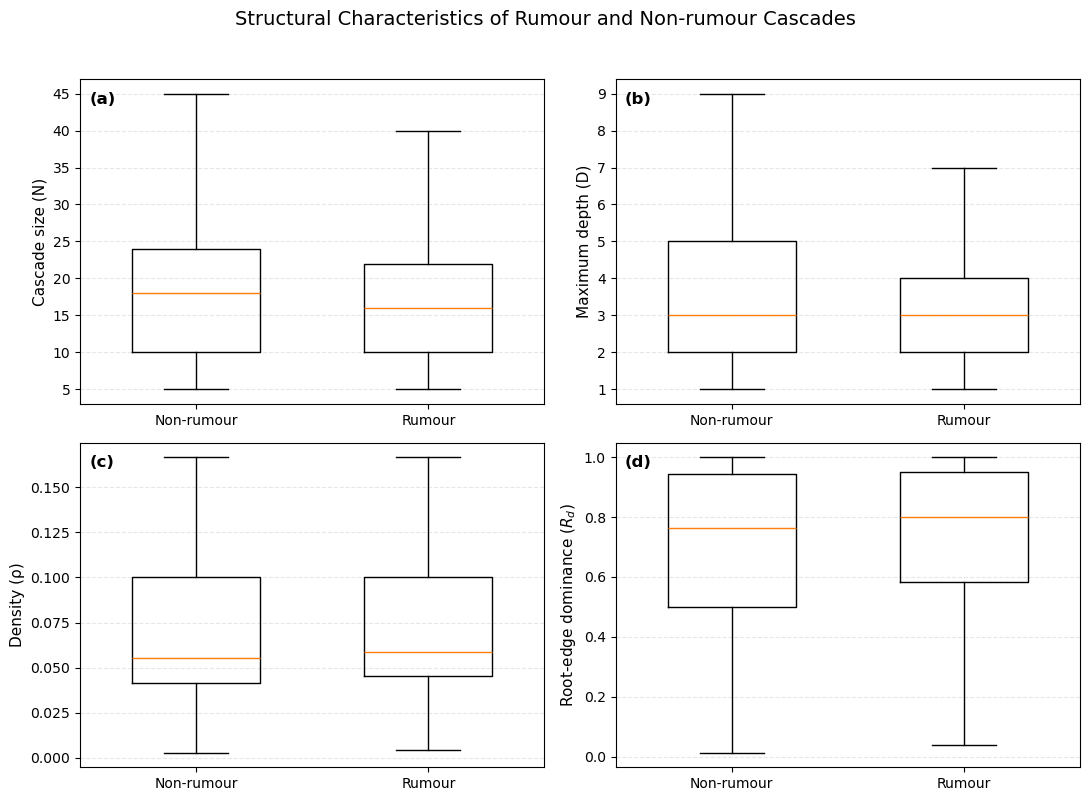

Figure saved as:
D:\PhD Material\Paper on Diffusion based  Node classification\Pheme\Update\Figure5_FINAL_4072.png
D:\PhD Material\Paper on Diffusion based  Node classification\Pheme\Update\Figure5_FINAL_4072.pdf


In [12]:
# ============================================================
# SECTION 3.5 — CELL 11
# FINAL FIGURE 5 — Corrected 4,072-cascade dataset
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import os

# ------------------------------------------------------------
# Prepare plotting data
# ------------------------------------------------------------

plot_df = df_corrected.copy()

plot_df["Class"] = plot_df["label"].map({
    0: "Non-rumour",
    1: "Rumour"
})

metrics = [
    ("n_nodes", "Cascade size (N)"),
    ("max_depth", "Maximum depth (D)"),
    ("density", "Density (ρ)"),
    ("root_edge_dominance", "Root-edge dominance ($R_d$)")
]

# ------------------------------------------------------------
# Create 2 × 2 figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 8)
)

axes = axes.flatten()

for ax, (column, ylabel) in zip(axes, metrics):

    non_rumour = plot_df.loc[
        plot_df["label"] == 0,
        column
    ]

    rumour = plot_df.loc[
        plot_df["label"] == 1,
        column
    ]

    ax.boxplot(
        [non_rumour, rumour],
        labels=["Non-rumour", "Rumour"],
        showfliers=False,
        widths=0.55
    )

    ax.set_ylabel(
        ylabel,
        fontsize=11
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.30
    )


# ------------------------------------------------------------
# Panel labels
# ------------------------------------------------------------

panel_labels = ["(a)", "(b)", "(c)", "(d)"]

for ax, panel in zip(axes, panel_labels):

    ax.text(
        0.02,
        0.96,
        panel,
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        va="top"
    )


# ------------------------------------------------------------
# Overall layout
# ------------------------------------------------------------

fig.suptitle(
    "Structural Characteristics of Rumour and Non-rumour Cascades",
    fontsize=14,
    y=0.995
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)


# ------------------------------------------------------------
# Save publication-quality versions
# ------------------------------------------------------------

output_folder = (
    r"D:\PhD Material\Paper on Diffusion based  Node classification"
    r"\Pheme\Update"
)

png_path = os.path.join(
    output_folder,
    "Figure5_FINAL_4072.png"
)

pdf_path = os.path.join(
    output_folder,
    "Figure5_FINAL_4072.pdf"
)

plt.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()


print("Figure saved as:")
print(png_path)
print(pdf_path)

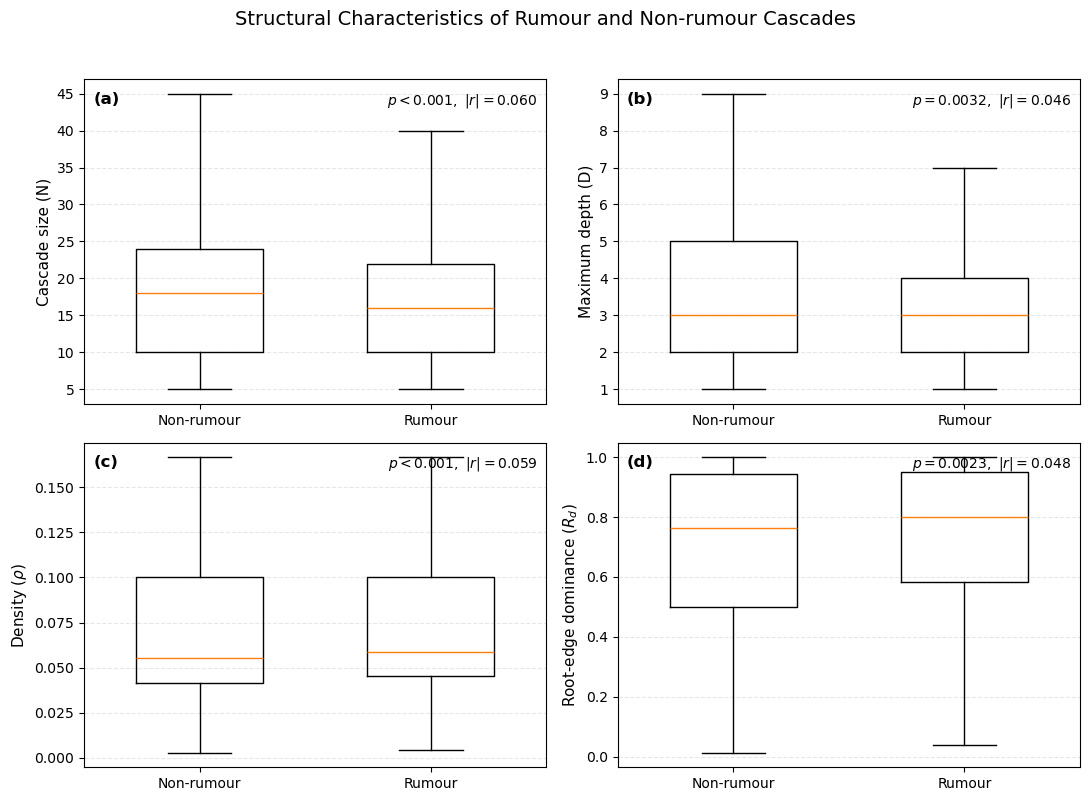

FINAL FIGURE 5 GENERATED

Dataset size: 4072

Class counts:
Class
Non-rumour    2851
Rumour        1221
Name: count, dtype: int64

Figure saved as:
D:\PhD Material\Paper on Diffusion based  Node classification\Pheme\Update\Figure5_FINAL_4072.png
D:\PhD Material\Paper on Diffusion based  Node classification\Pheme\Update\Figure5_FINAL_4072.pdf


In [13]:
# ============================================================
# SECTION 3.5 — FINAL FIGURE 5
# Structural characteristics of rumour and non-rumour cascades
# Verified final dataset: N = 4,072
# ============================================================

import matplotlib.pyplot as plt
import os

# ------------------------------------------------------------
# Prepare plotting dataframe
# ------------------------------------------------------------

plot_df = df_corrected.copy()

plot_df["Class"] = plot_df["label"].map({
    0: "Non-rumour",
    1: "Rumour"
})


# ------------------------------------------------------------
# Metrics to plot
# ------------------------------------------------------------

metrics = [
    ("n_nodes", "Cascade size (N)"),
    ("max_depth", "Maximum depth (D)"),
    ("density", "Density ($\\rho$)"),
    ("root_edge_dominance", "Root-edge dominance ($R_d$)")
]


# ------------------------------------------------------------
# Final Mann–Whitney results for plotted metrics
# ------------------------------------------------------------

test_annotations = [
    r"$p<0.001,\ |r|=0.060$",
    r"$p=0.0032,\ |r|=0.046$",
    r"$p<0.001,\ |r|=0.059$",
    r"$p=0.0023,\ |r|=0.048$"
]


# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11, 8)
)

axes = axes.flatten()


# ------------------------------------------------------------
# Draw boxplots
# ------------------------------------------------------------

for ax, (column, ylabel) in zip(axes, metrics):

    non_rumour = plot_df.loc[
        plot_df["label"] == 0,
        column
    ]

    rumour = plot_df.loc[
        plot_df["label"] == 1,
        column
    ]

    ax.boxplot(
        [non_rumour, rumour],
        labels=["Non-rumour", "Rumour"],
        showfliers=False,
        widths=0.55
    )

    ax.set_ylabel(
        ylabel,
        fontsize=11
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.30
    )


# ------------------------------------------------------------
# Panel labels
# ------------------------------------------------------------

panel_labels = [
    "(a)",
    "(b)",
    "(c)",
    "(d)"
]

for ax, panel in zip(axes, panel_labels):

    ax.text(
        0.02,
        0.96,
        panel,
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        ha="left",
        va="top"
    )


# ------------------------------------------------------------
# Statistical annotations
# ------------------------------------------------------------

for ax, annotation in zip(
    axes,
    test_annotations
):

    ax.text(
        0.98,
        0.96,
        annotation,
        transform=ax.transAxes,
        fontsize=10,
        ha="right",
        va="top"
    )


# ------------------------------------------------------------
# Overall title
# ------------------------------------------------------------

fig.suptitle(
    "Structural Characteristics of Rumour and Non-rumour Cascades",
    fontsize=14,
    y=0.995
)


# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)


# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

output_folder = (
    r"D:\PhD Material\Paper on Diffusion based  Node classification"
    r"\Pheme\Update"
)

png_path = os.path.join(
    output_folder,
    "Figure5_FINAL_4072.png"
)

pdf_path = os.path.join(
    output_folder,
    "Figure5_FINAL_4072.pdf"
)

plt.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

plt.show()


# ------------------------------------------------------------
# Confirmation
# ------------------------------------------------------------

print("=" * 70)
print("FINAL FIGURE 5 GENERATED")
print("=" * 70)

print("\nDataset size:", len(plot_df))

print("\nClass counts:")
print(
    plot_df["Class"].value_counts()
)

print("\nFigure saved as:")
print(png_path)
print(pdf_path)

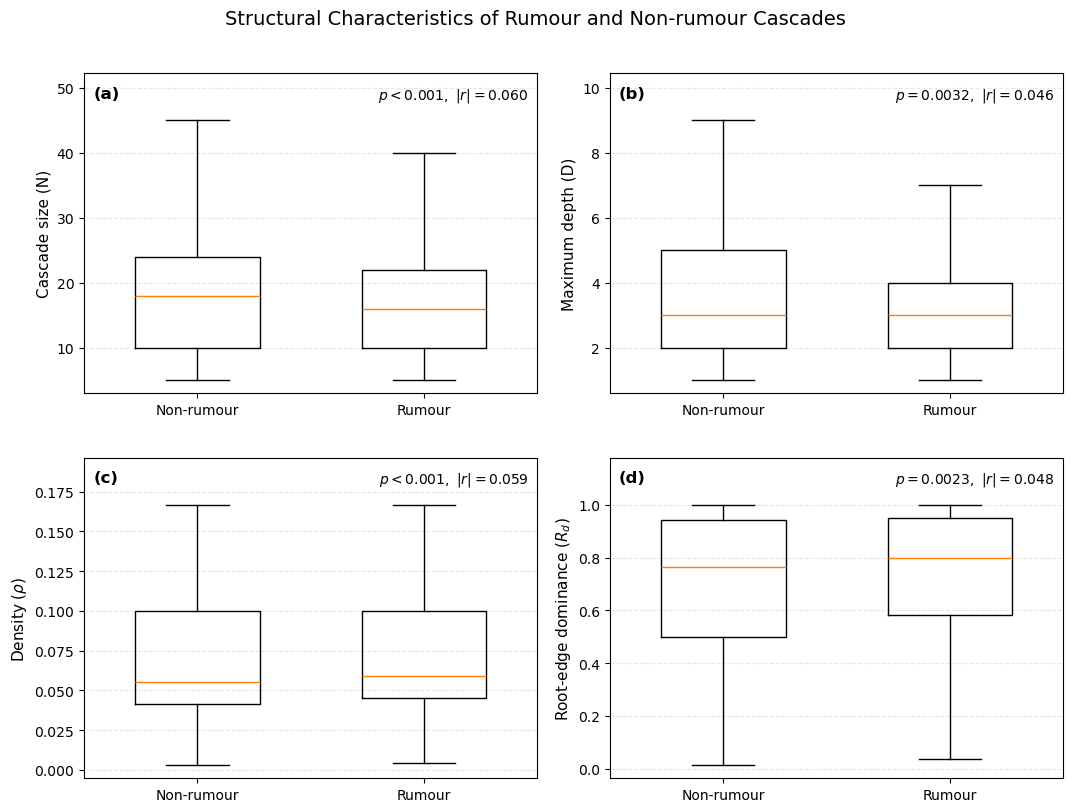

FINAL FIGURE 5 GENERATED
Dataset size: 4072

Class counts:
Class
Non-rumour    2851
Rumour        1221
Name: count, dtype: int64

Saved:
D:\PhD Material\Paper on Diffusion based  Node classification\Pheme\Update\Figure5_FINAL_4072.png
D:\PhD Material\Paper on Diffusion based  Node classification\Pheme\Update\Figure5_FINAL_4072.pdf


In [14]:
# ============================================================
# SECTION 3.5 — FINAL FIGURE 5
# Clean publication version
# Verified final dataset: N = 4,072
# ============================================================

import matplotlib.pyplot as plt
import os

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

plot_df = df_corrected.copy()

plot_df["Class"] = plot_df["label"].map({
    0: "Non-rumour",
    1: "Rumour"
})

metrics = [
    ("n_nodes", "Cascade size (N)"),
    ("max_depth", "Maximum depth (D)"),
    ("density", "Density ($\\rho$)"),
    ("root_edge_dominance", "Root-edge dominance ($R_d$)")
]

test_annotations = [
    r"$p<0.001,\ |r|=0.060$",
    r"$p=0.0032,\ |r|=0.046$",
    r"$p<0.001,\ |r|=0.059$",
    r"$p=0.0023,\ |r|=0.048$"
]

panel_labels = ["(a)", "(b)", "(c)", "(d)"]


# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11, 8.5)
)

axes = axes.flatten()


# ------------------------------------------------------------
# Draw plots
# ------------------------------------------------------------

for ax, (column, ylabel), panel, annotation in zip(
    axes,
    metrics,
    panel_labels,
    test_annotations
):

    non_rumour = plot_df.loc[
        plot_df["label"] == 0,
        column
    ]

    rumour = plot_df.loc[
        plot_df["label"] == 1,
        column
    ]

    ax.boxplot(
        [non_rumour, rumour],
        labels=["Non-rumour", "Rumour"],
        showfliers=False,
        widths=0.55
    )

    ax.set_ylabel(
        ylabel,
        fontsize=11
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.30
    )

    # --------------------------------------------------------
    # Add extra vertical space above data
    # --------------------------------------------------------

    ymin, ymax = ax.get_ylim()
    yrange = ymax - ymin

    ax.set_ylim(
        ymin,
        ymax + 0.12 * yrange
    )

    # --------------------------------------------------------
    # Panel label — upper left
    # --------------------------------------------------------

    ax.text(
        0.02,
        0.96,
        panel,
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        ha="left",
        va="top"
    )

    # --------------------------------------------------------
    # Statistical result — upper right
    # --------------------------------------------------------

    ax.text(
        0.98,
        0.96,
        annotation,
        transform=ax.transAxes,
        fontsize=10,
        ha="right",
        va="top"
    )


# ------------------------------------------------------------
# Main title
# ------------------------------------------------------------

fig.suptitle(
    "Structural Characteristics of Rumour and Non-rumour Cascades",
    fontsize=14,
    y=0.985
)


# ------------------------------------------------------------
# Increase spacing between panels
# ------------------------------------------------------------

plt.subplots_adjust(
    left=0.09,
    right=0.98,
    bottom=0.08,
    top=0.91,
    wspace=0.16,
    hspace=0.20
)


# ------------------------------------------------------------
# Save publication-quality files
# ------------------------------------------------------------

output_folder = (
    r"D:\PhD Material\Paper on Diffusion based  Node classification"
    r"\Pheme\Update"
)

png_path = os.path.join(
    output_folder,
    "Figure5_FINAL_4072.png"
)

pdf_path = os.path.join(
    output_folder,
    "Figure5_FINAL_4072.pdf"
)

plt.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Confirmation
# ------------------------------------------------------------

print("=" * 70)
print("FINAL FIGURE 5 GENERATED")
print("=" * 70)

print("Dataset size:", len(plot_df))

print("\nClass counts:")
print(plot_df["Class"].value_counts())

print("\nSaved:")
print(png_path)
print(pdf_path)

In [15]:
# ============================================================
# SECTION 4.1 — FINAL DESCRIPTIVE STATISTICS
# Verified 4,072-cascade dataset
# ============================================================

metrics_41 = [
    "n_nodes",
    "max_depth",
    "leaf_ratio",
    "mean_branching_internal",
    "density",
    "root_edge_dominance"
]

descriptive_41 = (
    df_corrected
    .groupby("label")[metrics_41]
    .mean()
    .T
)

descriptive_41.columns = [
    "Non-rumour",
    "Rumour"
]

print("=" * 70)
print("SECTION 4.1 — FINAL CLASS-WISE MEANS")
print("=" * 70)

display(
    descriptive_41.style.format("{:.6f}")
)

SECTION 4.1 — FINAL CLASS-WISE MEANS


,Non-rumour,Rumour
n_nodes,21.925991,19.031941
max_depth,4.316380,3.819820
leaf_ratio,0.708173,0.724855
mean_branching_internal,4.871505,4.861112
density,0.072709,0.077906
root_edge_dominance,0.699325,0.734103


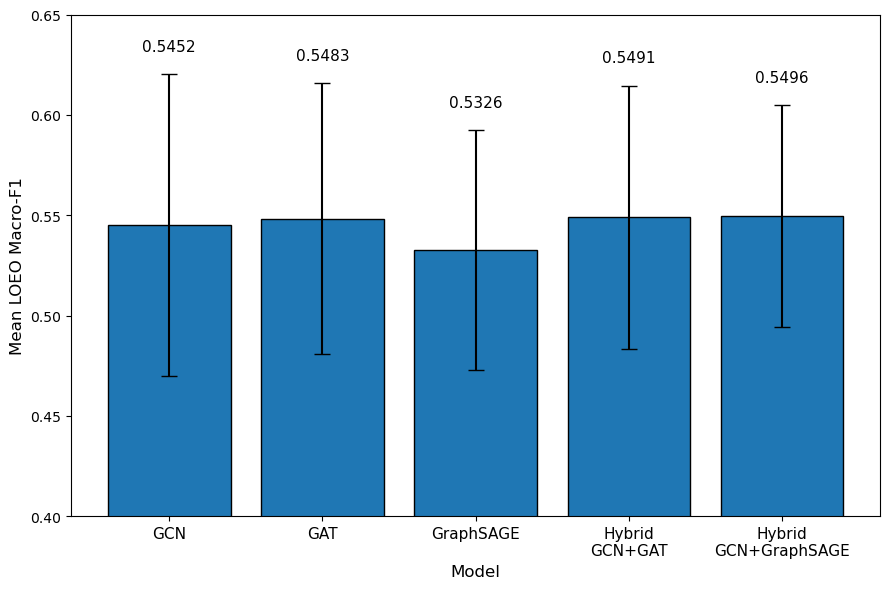

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Mean LOEO Macro-F1 and standard deviation across 4 held-out events
models = [
    "GCN",
    "GAT",
    "GraphSAGE",
    "Hybrid\nGCN+GAT",
    "Hybrid\nGCN+GraphSAGE"
]

mean_f1 = [0.5452, 0.5483, 0.5326, 0.5491, 0.5496]
std_f1  = [0.0751, 0.0674, 0.0598, 0.0655, 0.0555]

x = np.arange(len(models))

plt.figure(figsize=(9, 6))

bars = plt.bar(
    x,
    mean_f1,
    yerr=std_f1,
    capsize=6,
    edgecolor="black"
)

# Add value labels above bars
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + std_f1[i] + 0.01,
        f"{mean_f1[i]:.4f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.xticks(x, models, fontsize=11)
plt.ylabel("Mean LOEO Macro-F1", fontsize=12)
plt.xlabel("Model", fontsize=12)
plt.ylim(0.40, 0.65)

plt.tight_layout()

# Save at 600 dpi
plt.savefig(
    "Figure8_LOEO_MacroF1_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

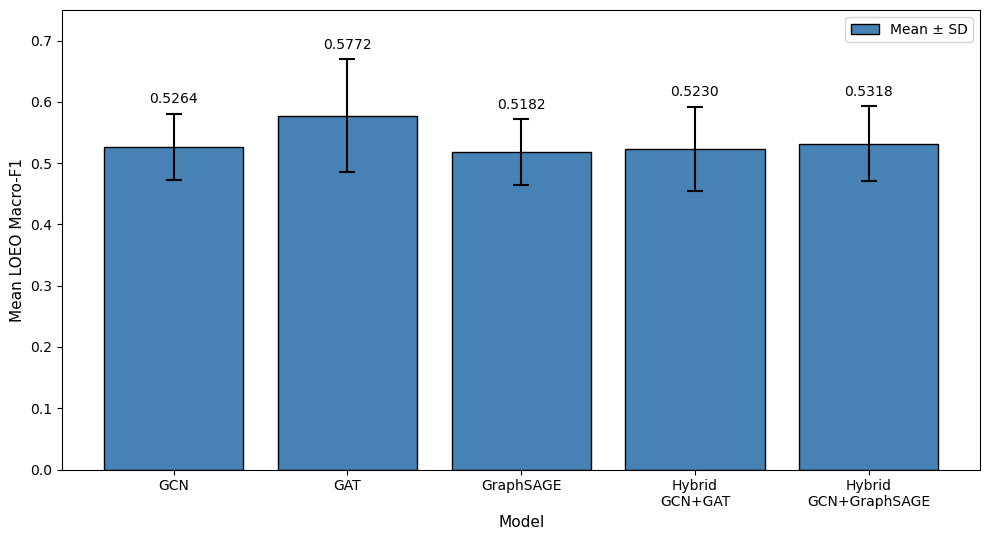

In [2]:

import numpy as np
import matplotlib.pyplot as plt

models = [
    "GCN",
    "GAT",
    "GraphSAGE",
    "Hybrid\nGCN+GAT",
    "Hybrid\nGCN+GraphSAGE"
]

mean_f1 = np.array([
    0.5264, 0.5772, 0.5182, 0.5230, 0.5318
])

std_f1 = np.array([
    0.0546, 0.0923, 0.0532, 0.0690, 0.0611
])

fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(models))

bars = ax.bar(
    x,
    mean_f1,
    yerr=std_f1,
    capsize=6,
    color="steelblue",
    edgecolor="black",
    linewidth=1,
    error_kw={"elinewidth": 1.5, "capthick": 1.5},
    label="Mean ± SD"
)

for bar, mean, sd in zip(bars, mean_f1, std_f1):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        mean + sd + 0.012,
        f"{mean:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=10)
ax.set_xlabel("Model", fontsize=11)
ax.set_ylabel("Mean LOEO Macro-F1", fontsize=11)
ax.set_ylim(0, 0.75)
ax.legend(loc="upper right")
ax.grid(False)

plt.tight_layout()

plt.savefig(
    "Figure8_Corrected_LOEO_MacroF1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "Figure8_Corrected_LOEO_MacroF1.pdf",
    bbox_inches="tight"
)

plt.show()


In [4]:
import pandas as pd
from sklearn.metrics import f1_score

df = pd.read_csv(r"D:\PhD Material\Paper on Diffusion based  Node classification\Network Science\Re-Review\Code-files\strict_loeo_all_predictions.csv")
models = [
    "GCN",
    "GAT",
    "GraphSAGE",
    "Hybrid_GCN_GAT",
    "Hybrid_GCN_GraphSAGE"
]

topologies = ["star", "hybrid", "chain"]

for model in models:
    print("\n", model)

    for topology in topologies:
        subset = df[
            (df["model"] == model) &
            (df["topology"] == topology)
        ]

        score = f1_score(
            subset["true_label"],
            subset["predicted_label"],
            average="macro"
        )

        print(topology, len(subset), round(score, 4))


 GCN
star 1950 0.522
hybrid 1661 0.4878
chain 461 0.5491

 GAT
star 1950 0.6304
hybrid 1661 0.5796
chain 461 0.6215

 GraphSAGE
star 1950 0.5216
hybrid 1661 0.5069
chain 461 0.5671

 Hybrid_GCN_GAT
star 1950 0.5176
hybrid 1661 0.5217
chain 461 0.5785

 Hybrid_GCN_GraphSAGE
star 1950 0.5268
hybrid 1661 0.5137
chain 461 0.5448
